# 4. Amazon India Apparel Sales: EDA Report

This report explores the cleaned Amazon India apparel sales data (orders from 31 Mar to 29 Jun 2022). It shows the main numbers, how the data is distributed, how sales move over time and across states, and answers two business questions: which categories get cancelled most, and how Amazon fulfilment compares with Merchant fulfilment. The SQL file answers the same questions with queries; here they are shown as charts.


In [88]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [89]:
df = pd.read_csv(r"G:\amazon-india-apparel-sales-analysis\Data\amazon_sales_clean.csv")
df.shape  #dimentions of data

(128968, 21)

## Key numbers

In [90]:
total_revenue = round(df["revenue"].sum())               # whole rupees
total_orders = df["order_id"].nunique()                  # unique orders
total_items = len(df)                                    # rows = items
cancel_rate = round((df["status"] == "Cancelled").mean() * 100, 2)   # 1 decimal

print("Total revenue : Rs", total_revenue)
print("Unique orders :", total_orders)
print("Items         :", total_items)
print("Cancel rate   :", cancel_rate, "%")

Total revenue : Rs 71821815
Unique orders : 120378
Items         : 128968
Cancel rate   : 14.21 %


# Univariate Analysis

### Order Status

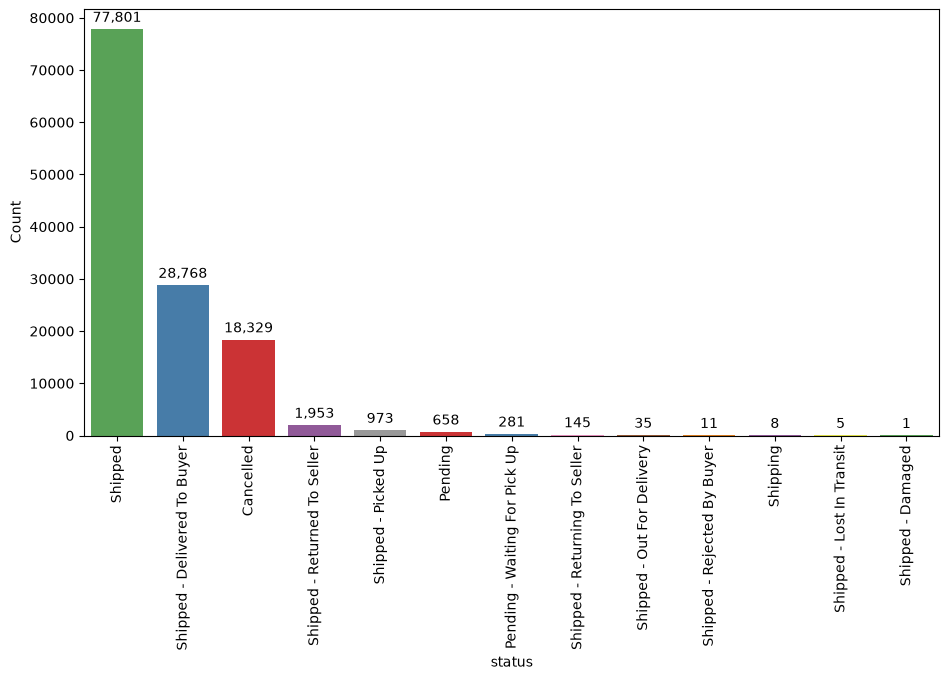

In [91]:
plt.figure(figsize =(10,5))
ax=sns.countplot(data=df,x="status", order=df["status"].value_counts().index ,palette="Set1",hue="status",legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3)
plt.ylabel("Count")
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

*Most items are shipped or delivered; cancelled is the third-largest status.*

### Category

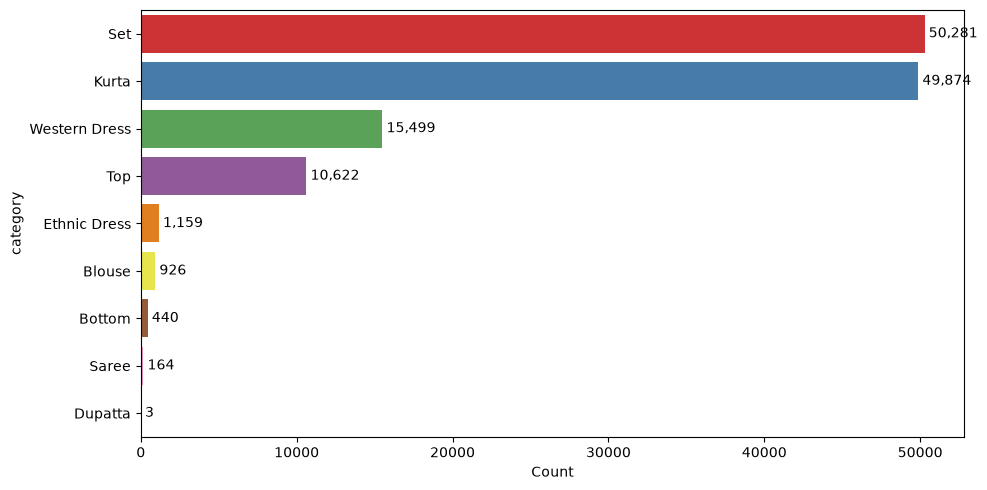

In [92]:
s = df["category"].value_counts()

plt.figure(figsize= (10,5))
ax = sns.barplot(x=s.values,y=s.index, hue=s.index, palette="Set1", legend=False)

for c in ax.containers:
    ax.bar_label(c,fmt="{:,.0f}",padding=3)
plt.xlabel("Count")
plt.tight_layout()
plt.show()

*Most sold category is 'Set' followed by 'Kurta' and 'Western Dresses'.*

### Size distribution


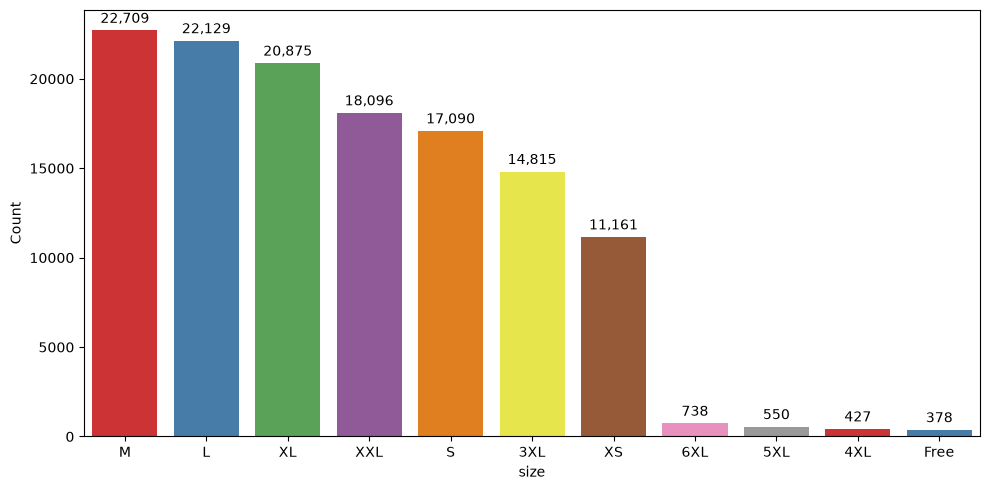

In [93]:
s = df["size"].value_counts()

plt.figure(figsize=(10,5))
ax = sns.barplot(x=s.index,y=s.values, palette="Set1", hue=s.index, legend= False)

for c in ax.containers:
    ax.bar_label(c,fmt= "{:,.0f}",padding=3)

plt.ylabel("Count")
plt.tight_layout()


plt.show()

*Medim size sold the most, whereas Free size is least sold.*

### Amount distribution

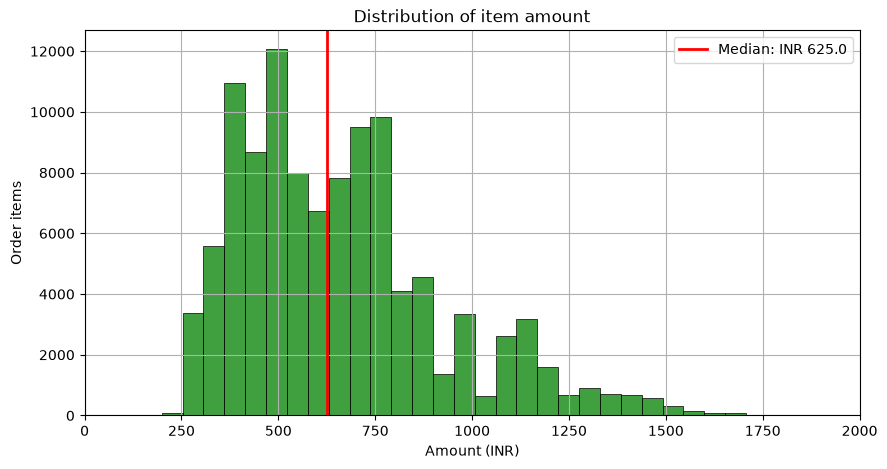

In [133]:
amt = df.loc[~(df["status"]== "Cancelled") & (df["amount"] > 0), "amount"]

median = amt.median().round(1)
plt.figure(figsize=(10,5))
sns.histplot(amt,bins= 100 ,color= "green")

plt.title("Distribution of item amount")
plt.xlabel("Amount (INR)")
plt.axvline(median, color = "red",linewidth = 2,label=f"Median: INR {median}")
plt.ylabel("Order items")
plt.xlim(0, 2000)
plt.legend()
plt.grid()
plt.show()


*Most items sell between about INR 400 and 800; a few expensive items stretch the right tail (the chart is cut at INR 1,600).*

# Time Analysis 

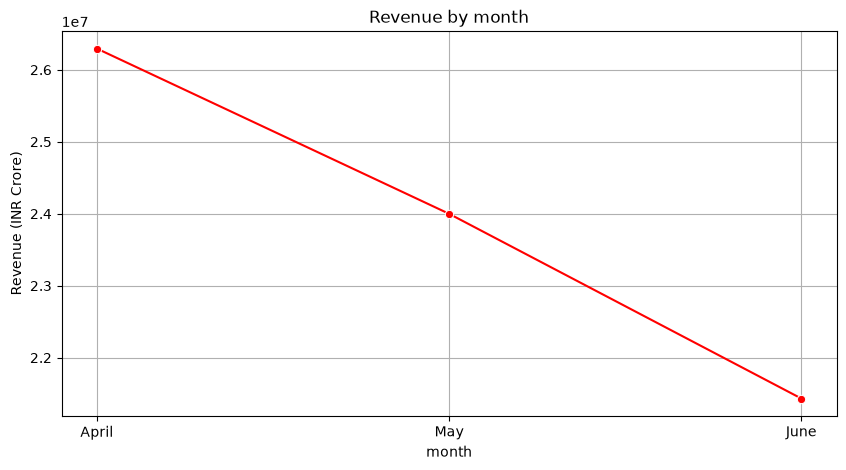

In [ ]:
month_name = ["April","May","June"]
s = df.groupby("month")["revenue"].sum().reindex(month_name).round(3)

plt.figure(figsize=(10,5))

sns.lineplot(x=s.index,y=s.values, marker = "o",color= "red")

plt.ylabel("Revenue (INR Crore)")
plt.grid()
plt.title("Revenue by month")
plt.show()

*April shows the highest revenue*

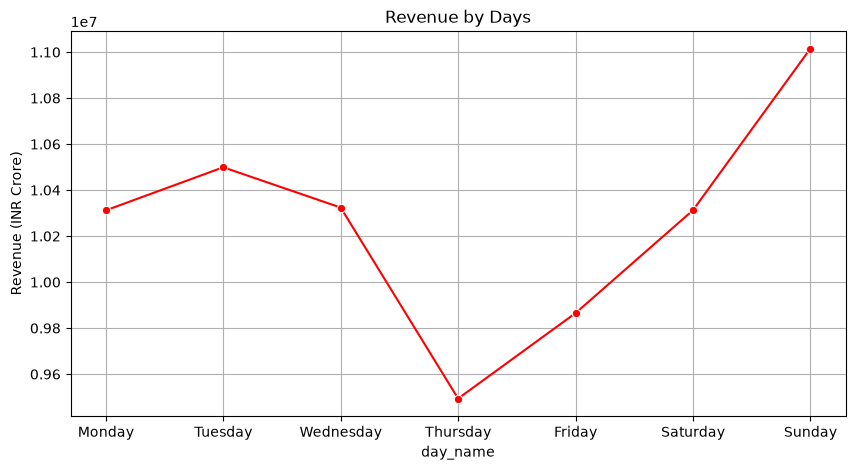

In [154]:
day_name = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
s = df.groupby("day_name")["revenue"].sum().reindex(day_name).round(3)

plt.figure(figsize=(10,5))

sns.lineplot(x=s.index,y=s.values, marker = "o",color= "red")

plt.ylabel("Revenue (INR Crore)")
plt.grid()
plt.title("Revenue by Days")
plt.show()

*Revenue shows decline in revenue on Thrusday*


*Revenue falls each month from April to June, and Sunday is the strongest weekday. March is left out because the data has only one day of it (31 Mar), and June ends on the 29th.*

# Geographical Analysis

<Figure size 1000x500 with 0 Axes>

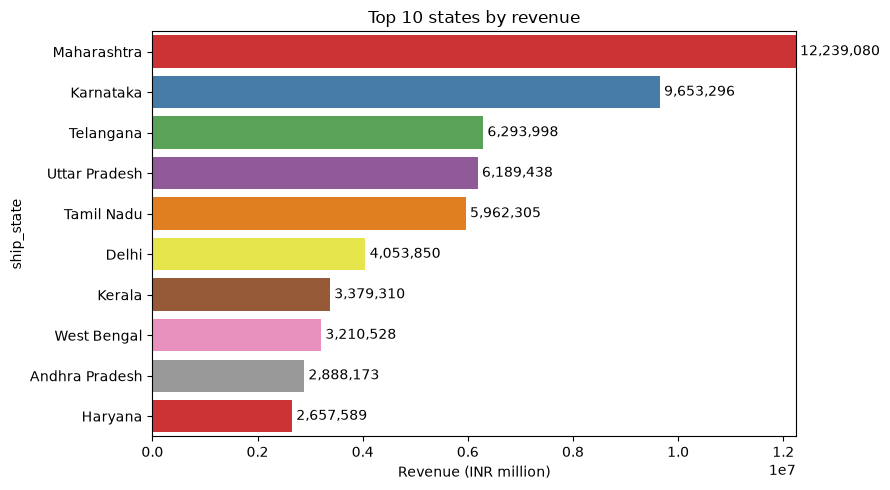

In [169]:
s = df.groupby("ship_state")["revenue"].sum().nlargest(10)
plt.figure(figsize=(10,5))
ax = plt.subplots(figsize=(9, 5))
ax= sns.barplot(x=s.values, y=s.index, palette="Set1", hue=s.index, legend=False)
for c in ax.containers:
    ax.bar_label(c,fmt= "{:,.0f}",padding=3)

plt.xlabel("Revenue (INR million)")
plt.title("Top 10 states by revenue")
ax.set_xlim(0, s.max())
plt.tight_layout()
plt.show()

*Maharashtra and Karnataka are far ahead of every other state.*

# Business Questions

#### **1. How many order items were cancelled, and how does that compare with shipped items?**

Most items were Shipped (77,801, 60.3%) or Delivered (28,768, 22.3%). Cancelled is the third-largest status with 18,329 items (14.2%). *(Order status chart)*

#### **2. Which categories get ordered the most?**

Set (50,281) and Kurta (49,874) together make up 77.7% of all order items. Western Dress is third with 15,499, and Top follows with 10,622. The other five categories are each under 1,200. *(Category chart)*

#### **3. Which sizes are the most popular?**

M (22,709), L (22,129) and XL (20,875) together are about 51% of order items. Free size is the smallest with 378, and the very large sizes (4XL to 6XL) are each under 740. *(Size chart)*

#### **4. What does a typical item cost?**

The median item amount is INR 625, and most items sell between about INR 400 and 800. About 11% of items cost more than INR 1,000, which stretches the right tail. *(Amount chart)*

#### **5. How did revenue change from April to June?**

Revenue fell every month, from INR 26.3 million in April to 24.0 million in May (-8.7%) and 21.4 million in June (-10.7%). March is left out because the data has only one day of it. *(Revenue by month chart)*

#### **6. Which day of the week earns the most, and which the least?**

Sunday is the strongest day with INR 11.0 million, and Thursday is the weakest with INR 9.5 million, so Sunday earns about 16% more. The other days are between INR 9.9 and 10.5 million. *(Revenue by day chart)*

#### **7. Which states bring in the most revenue?**

Maharashtra leads with INR 12.2 million (17.0% of total revenue), followed by Karnataka with 9.7 million (13.4%). Telangana, Uttar Pradesh and Tamil Nadu come next at about 6 million each. *(Top 10 states chart)*

#### **8. Overall, what does the typical business look like?**

Most order items are Sets or Kurtas (77.7%), in sizes M, L and XL (about 51%), priced around INR 625. Sales are concentrated in a few states and have been falling since April.

# Insights

- **Most orders go through, but about 1 in 7 is cancelled.** Of 128,968 order items, 60.3% were shipped and 22.3% were delivered. Cancelled items are the third-largest group, with 18,329 items (14.2%). Only 1.5% were returned to the seller.
- **The business depends on two categories and three sizes.** Set and Kurta together are 77.7% of all order items (50,281 and 49,874). Sizes M, L and XL are 51% of items, while the largest sizes (4XL to 6XL) and Free size are each under 740 items.
- **Revenue fell every month.** It dropped from INR 26.3 million in April to 24.0 million in May (-8.7%) and 21.4 million in June (-10.7%). This is not just fewer days: revenue per day fell from about INR 876k in April to 739k in June (-15.7%).
- **Sunday is the best day and Thursday is the worst.** Sunday earns INR 11.0 million and Thursday INR 9.5 million, so Sunday earns about 16% more. The other days are close together, between INR 9.9 and 10.5 million.
- **Sales come from a few states.** Maharashtra (INR 12.2 million, 17.0%) and Karnataka (INR 9.7 million, 13.4%) together bring in 30.5% of revenue, and the top 10 states bring in 78.7%.
- **Customers buy mid-priced items.** The median item amount is INR 625, and half of all items cost between INR 459 and 788. Only about 11% of items cost more than INR 1,000.

# Conclusion

This business sells mostly Sets and Kurtas, in sizes M, L and XL, at around INR 625 per item, and a few states (led by Maharashtra and Karnataka) bring in most of the revenue. The main concern is that revenue has fallen every month from April to June, and the 14.2% cancel rate means that about 1 in 7 items never reaches the customer. The next step is to find out why revenue is falling, for example by checking whether the drop is in Sets and Kurtas or in particular states, and what drives the cancellations.